# Bias Waktu Trigger STA/LTA akibat Fase Filter: FIR vs IIR pada Erupsi Kelud 2014 (GE.JAGI)

**Mata kuliah:** Pengolahan Sinyal Digital 2026 &nbsp;|&nbsp; **Data:** GEOFON, jaringan GE, stasiun JAGI, kanal BHZ, 20 Hz (13 Feb 2014)

## Pertanyaan penelitian
Filter bandpass dipakai sebelum detektor STA/LTA untuk membuang derau. Tetapi filter juga **menggeser fase**. Berapa detik waktu trigger bergeser karena fase filter, dan apakah pergeseran itu sesuai dengan prediksi teori *group delay*?

## Alur notebook
| Bagian | Isi | Tujuan |
|---|---|---|
| 1 | Muat data dan cek | Pastikan data valid |
| 2 | Desain filter FIR dan IIR + group delay + pole-zero | Teori (materi Filter FIR/IIR, Transformasi Z) |
| 3 | STA/LTA dari nol + uji sanitas | Detektor yang kita ukur |
| 4 | **Eksperimen A: onset sintetis (ground truth buatan sendiri)** | Mengukur bias fase dengan jawaban yang diketahui |
| 5 | **Eksperimen B: data nyata Kelud** | Membuktikan temuan A berlaku di data sungguhan |
| 6 | Opsional: koreksi respons instrumen | Uji sensitivitas |
| 7 | Ringkasan untuk laporan + daftar pustaka | Bahan menulis |

> Semua gambar otomatis tersimpan di folder `figures/` (siap dimasukkan ke laporan dan slide).

## 1. Persiapan dan data

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import signal
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

FS = 20.0
CSV_PATH = "kelud2014_JAGI_BHZ_gabungan.csv"

if not Path(CSV_PATH).exists():
    try:
        from google.colab import files
        print("Upload file", CSV_PATH); files.upload()
    except ImportError:
        raise FileNotFoundError(f"Taruh {CSV_PATH} satu folder dengan notebook ini.")

In [2]:
df = pd.read_csv(CSV_PATH, parse_dates=["waktu_utc"])
x_all = df["counts"].to_numpy(float)
is_warm = (df["segmen"] == "warmup").to_numpy()
T0_UTC = df["waktu_utc"].iloc[0]

def utc(i):
    """indeks sampel -> waktu UTC (pandas Timestamp)"""
    return T0_UTC + pd.to_timedelta(np.asarray(i) / FS, unit="s")

dt = np.diff(df["detik_dari_awal"].to_numpy())
print(f"Sampel : {len(df):,} durasi {len(df)/FS/3600:.2f} jam")
print(f"dt unik : {np.unique(np.round(dt,3))} s  (harus 0.05 -> tidak ada gap)")
print(f"Warm-up : {is_warm.sum():,} sampel ({is_warm.sum()/FS/3600:.2f} jam)  |  Analisis: {(~is_warm).sum():,} sampel")
print(f"Counts : min {x_all.min():.0f}  max {x_all.max():.0f}  median {np.median(x_all):.0f}")
assert np.allclose(dt, 1/FS, atol=1e-3), "ada gap/ketidakteraturan waktu!"

Sampel : 594,429  |  durasi 8.26 jam
dt unik : [0.05] s  (harus 0.05 -> tidak ada gap)
Warm-up : 162,292 sampel (2.25 jam)  |  Analisis: 432,137 sampel
Counts : min 19  max 3783  median 1626


## 2. Desain filter dan teori *group delay*

Dua filter bandpass **0,5–5 Hz** (pita yang umum untuk deteksi tremor/gempa vulkanik pada stasiun regional):

* **FIR fase-linear**: jendela Hamming, 201 koefisien. Group delay **konstan** = (N−1)/2 sampel = 5,0 s untuk semua frekuensi.
* **IIR Butterworth orde 4** (bentuk SOS, stabil secara numerik). Group delay **bergantung frekuensi**, membesar di tepi pita.

Untuk sinyal pita sempit berfrekuensi f₀, onset bergeser kira-kira sebesar **τ_g(f₀) = −dφ/dω**. Inilah prediksi teori yang nanti kita uji.

Empat perlakuan yang dibandingkan:

| Nama | Cara | Fase |
|---|---|---|
| FIR kausal | `lfilter` tanpa kompensasi | linear, tertunda 5 s |
| FIR terkompensasi | konvolusi `mode="same"` | nol (efektif, akausal) |
| IIR kausal | `sosfilt` | non-linear (real-time) |
| IIR filtfilt | `sosfiltfilt` | nol, tapi magnitudo menjadi \|H\|² |
| **Referensi fase-nol \|H\|** | FFT dikali \|H(f)\| IIR | nol, magnitudo **sama persis** dengan IIR kausal |

Perlakuan terakhir adalah kunci desain: selisih **IIR kausal − Referensi** hanya berasal dari **fase**, bukan dari bentuk magnitudo.

In [3]:
F_LO, F_HI = 0.5, 5.0
N_FIR = 201; M_FIR = (N_FIR - 1) // 2

b_fir = signal.firwin(N_FIR, [F_LO, F_HI], pass_zero=False, fs=FS, window="hamming")
sos = signal.butter(4, [F_LO, F_HI], btype="bandpass", fs=FS, output="sos")

def group_delay_sos(sos, f_hz, n=400_000):
    """Group delay (detik) filter SOS pada frekuensi f_hz, dari turunan fase: tau = -dphi/domega."""
    w, h = signal.sosfreqz(sos, worN=np.linspace(1e-3, np.pi - 1e-3, n))
    phi = np.unwrap(np.angle(h))
    tau = -np.gradient(phi, w) / FS
    return np.interp(f_hz, w * FS / (2 * np.pi), tau)

print("Group delay IIR (teori):")
for f in [0.5, 0.6, 0.7, 0.8, 1, 2, 3, 4, 5]:
    print(f"  f = {f:>3} Hz  ->  {group_delay_sos(sos, f):6.3f} s")
print(f"Group delay FIR (konstan): {M_FIR/FS:.3f} s")

Group delay IIR (teori):
  f = 0.5 Hz  ->   1.383 s
  f = 0.6 Hz  ->   1.020 s
  f = 0.7 Hz  ->   0.689 s
  f = 0.8 Hz  ->   0.501 s
  f =   1 Hz  ->   0.320 s
  f =   2 Hz  ->   0.137 s
  f =   3 Hz  ->   0.125 s
  f =   4 Hz  ->   0.163 s
  f =   5 Hz  ->   0.216 s
Group delay FIR (konstan): 5.000 s


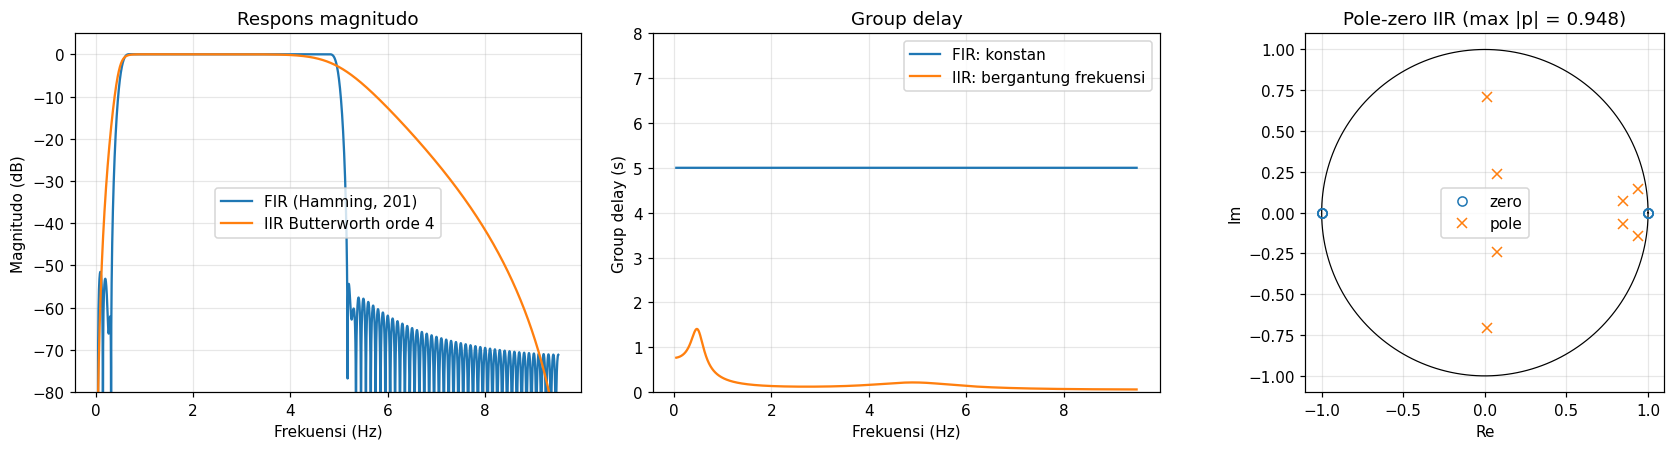

IIR stabil (semua |pole| < 1): True


In [4]:
f = np.linspace(0.05, 9.5, 4000)
w, h_iir = signal.sosfreqz(sos, worN=2*np.pi*f/FS)
_, h_fir = signal.freqz(b_fir, 1, worN=2*np.pi*f/FS)
gd_iir = group_delay_sos(sos, f); gd_fir = np.full_like(f, M_FIR/FS)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(f, 20*np.log10(np.abs(h_fir)+1e-12), label="FIR (Hamming, 201)")
ax[0].plot(f, 20*np.log10(np.abs(h_iir)+1e-12), label="IIR Butterworth orde 4")
ax[0].set(ylim=(-80, 5), xlabel="Frekuensi (Hz)", ylabel="Magnitudo (dB)", title="Respons magnitudo"); ax[0].legend()

ax[1].plot(f, gd_fir, label="FIR: konstan"); ax[1].plot(f, gd_iir, label="IIR: bergantung frekuensi")
ax[1].set(ylim=(0, 8), xlabel="Frekuensi (Hz)", ylabel="Group delay (s)", title="Group delay"); ax[1].legend()

z, p, k = signal.sos2zpk(sos)
th = np.linspace(0, 2*np.pi, 400); ax[2].plot(np.cos(th), np.sin(th), "k-", lw=.8)
ax[2].plot(z.real, z.imag, "o", mfc="none", label="zero"); ax[2].plot(p.real, p.imag, "x", label="pole")
ax[2].set(aspect="equal", xlabel="Re", ylabel="Im", title=f"Pole-zero IIR (max |p| = {np.abs(p).max():.3f})"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR/"01_filter_respons_gd_polezero.png", bbox_inches="tight"); plt.show()
print("IIR stabil (semua |pole| < 1):", bool(np.all(np.abs(p) < 1)))

## 3. STA/LTA dari nol

Fungsi karakteristik (CF) = rata-rata **energi** pada jendela pendek (STA) dibagi jendela panjang (LTA). Parameter awal: **STA 3 s, LTA 60 s** (bisa diubah; Nur dkk. 2025 memakai 10/35 s, Arifin & Nugraha 2015 memakai 0,5/60 s). Trigger aktif saat CF melewati ambang ON.

Opsi `lta_includes_sta=True` = definisi klasik (Allen 1978; sama dengan `classic_sta_lta` ObsPy). Jika `False`, LTA diambil dari jendela **sebelum** STA.

In [5]:
NS, NL = int(3*FS), int(60*FS)

def sta_lta(y, ns=NS, nl=NL, lta_includes_sta=True):
    """STA/LTA energi, kausal. Mengembalikan array CF (NaN di awal)."""
    p = y.astype(float) ** 2
    c = np.concatenate(([0.0], np.cumsum(p)))
    n = len(p); cf = np.full(n, np.nan)
    start = nl - 1 if lta_includes_sta else nl + ns - 1
    i = np.arange(start, n)
    sta = (c[i + 1] - c[i + 1 - ns]) / ns
    if lta_includes_sta:
        lta = (c[i + 1] - c[i + 1 - nl]) / nl
    else:
        lta = (c[i - ns + 1] - c[i - ns + 1 - nl]) / nl
    cf[i] = sta / (lta + 1e-12)
    return cf

def detect_events(cf, on, off, min_gap_s=120):
    """Daftar event: (i_on, i_off, cf_max). Event dibuka saat CF>=on, ditutup saat CF<off."""
    ok = ~np.isnan(cf); above = ok & (np.nan_to_num(cf) >= on)
    rising = np.flatnonzero(above & ~np.r_[False, above[:-1]])
    ev, last_end = [], -10**12
    for i0 in rising:
        if i0 < last_end + min_gap_s * FS: continue
        j = np.flatnonzero(np.nan_to_num(cf[i0:], nan=0) < off)
        i1 = i0 + (j[0] if j.size else len(cf) - i0 - 1)
        ev.append((i0, i1, float(np.nanmax(cf[i0:i1 + 1])))); last_end = i1
    return ev

rng_t = np.random.default_rng(0); n_t = int(400*FS)
sig_t = rng_t.normal(0, 1, n_t); i_onset = int(250*FS)
sig_t[i_onset:i_onset + int(30*FS)] += 8*np.sin(2*np.pi*2*np.arange(int(30*FS))/FS)
cf_t = sta_lta(sig_t); trig = np.flatnonzero(cf_t >= 3)[0]
print(f"Onset di {i_onset/FS:.1f} s, trigger di {trig/FS:.2f} s  (jeda {(trig-i_onset)/FS:.2f} s)")
assert 0 <= (trig - i_onset)/FS < 3, "STA/LTA tidak berperilaku wajar"

Onset di 250.0 s, trigger di 250.15 s  (jeda 0.15 s)


## 4. Eksperimen A: onset sintetis (ground truth buatan sendiri)

**Masalah:** untuk JAGI tidak ada katalog resmi waktu tiba, jadi "bias" tidak punya pembanding. **Solusi:** kita tanam sinyal buatan dengan **waktu onset yang kita tentukan** ke dalam derau asli JAGI (segmen *warm-up*, 2,25 jam sebelum erupsi), lalu mengukur selisih antara waktu trigger dan onset sebenarnya.

Rancangan:
* Wavelet: sinusoid teredam f₀ dengan kenaikan awal 0,5 s (mirip onset emergent), puncak dinormalkan menjadi 1.
* **SNR** = amplitudo puncak / RMS derau di dalam pita 0,5–5 Hz.
* Onset acak (termasuk **sub-sampel**) di 100 posisi derau berbeda per kondisi (Monte Carlo).
* **Penjaga:** trial dibuang jika derau *saja* sudah memicu trigger di jendela uji pada pipeline mana pun. Dengan begitu pemicu palsu tidak ikut dihitung sebagai bias.
* Bias = waktu trigger − waktu onset sebenarnya. **Efek fase murni** = IIR kausal − Referensi fase-nol \|H\|, dibandingkan dengan τ_g(f₀) teori.

> Catatan: delay mutlak trigger juga bergantung pada **SNR** dan lebar STA (algoritma STA/LTA sendiri tertinggal). Karena itu kita lihat bias sebagai fungsi SNR, dan efek fase diisolasi lewat selisih berpasangan.

In [6]:
_mag_cache = {}
def zero_phase_magnitude(x):
    """Filter fase-nol dengan magnitudo |H(f)| IIR (dikali di domain frekuensi)."""
    n = len(x)
    if n not in _mag_cache:
        fr = np.fft.rfftfreq(n, 1/FS)
        _mag_cache[n] = np.abs(signal.sosfreqz(sos, worN=2*np.pi*fr/FS)[1])
    return np.fft.irfft(np.fft.rfft(x) * _mag_cache[n], n=n)

PIPE_NAMES = ["FIR kausal", "FIR terkompensasi", "IIR kausal", "IIR filtfilt", "Ref fase-nol |H| IIR"]
def apply_pipelines(x):
    return {"FIR kausal": signal.lfilter(b_fir, 1.0, x),
            "FIR terkompensasi": np.convolve(x, b_fir, mode="same"),
            "IIR kausal": signal.sosfilt(sos, x),
            "IIR filtfilt": signal.sosfiltfilt(sos, x),
            "Ref fase-nol |H| IIR": zero_phase_magnitude(x)}

def synth_wavelet(t, f0, tau=4.0, rise=0.5):
    s = np.zeros_like(t); m = t >= 0; tt = t[m]
    s[m] = (1 - np.exp(-tt/rise)) * np.exp(-tt/tau) * np.sin(2*np.pi*f0*tt)
    return s / np.max(np.abs(s))

NOISE = x_all[is_warm]
LEAD, TAIL, ON_A = 150, 80, 3.0
rng = np.random.default_rng(2014)

def run_condition(f0, snr, n_trial):
    out = {k: [] for k in PIPE_NAMES}; tried = 0
    while len(out[PIPE_NAMES[0]]) < n_trial:
        tried += 1
        i0 = rng.integers(int(LEAD*FS) + 10, len(NOISE) - int(TAIL*FS) - 10)
        seg = signal.detrend(NOISE[i0 - int(LEAD*FS): i0 + int(TAIL*FS)])
        frac = rng.random()
        t = (np.arange(len(seg)) - LEAD*FS - frac) / FS
        rms = np.std(zero_phase_magnitude(seg)[int(60*FS):int(140*FS)])
        sig = snr * rms * synth_wavelet(t, f0)
        win = slice(int((LEAD-40)*FS), int((LEAD+60)*FS))
        if any(np.nanmax(sta_lta(y)[win]) >= ON_A for y in apply_pipelines(seg).values()):
            continue
        for k, y in apply_pipelines(seg + sig).items():
            w = sta_lta(y)[int((LEAD-30)*FS): int((LEAD+60)*FS)]
            hit = np.flatnonzero(w >= ON_A)
            out[k].append(hit[0]/FS - 30 - frac/FS if hit.size else np.nan)
    return {k: np.array(v) for k, v in out.items()}, tried

N_TRIAL = 100
F0_LIST  = [0.6, 0.8, 1.0, 2.0, 3.0, 4.0]
SNR_LIST = [4, 8, 16]

rows = []
for f0 in F0_LIST:
    for snr in SNR_LIST:
        r, tried = run_condition(f0, snr, N_TRIAL)
        for k, v in r.items():
            rows.append(dict(f0=f0, snr=snr, pipeline=k, bias_mean=np.nanmean(v), bias_sd=np.nanstd(v),
                             miss=int(np.isnan(v).sum()), n=len(v)))
        d = r["IIR kausal"] - r["Ref fase-nol |H| IIR"]
        rows.append(dict(f0=f0, snr=snr, pipeline="EFEK FASE IIR (kausal - ref)", bias_mean=np.nanmean(d),
                         bias_sd=np.nanstd(d), miss=int(np.isnan(d).sum()), n=len(d)))
        print(f"f0={f0} Hz  SNR={snr:>2}  selesai (percobaan {tried}, dibuang {tried-N_TRIAL})")
resA = pd.DataFrame(rows)
resA["gd_teori_iir"] = [float(group_delay_sos(sos, f)) for f in resA["f0"]]
resA.to_csv("hasil_eksperimen_A.csv", index=False)

f0=0.6 Hz  SNR= 4  selesai (percobaan 291, dibuang 191)
f0=0.6 Hz  SNR= 8  selesai (percobaan 373, dibuang 273)
f0=0.6 Hz  SNR=16  selesai (percobaan 392, dibuang 292)
f0=0.8 Hz  SNR= 4  selesai (percobaan 319, dibuang 219)
f0=0.8 Hz  SNR= 8  selesai (percobaan 334, dibuang 234)
f0=0.8 Hz  SNR=16  selesai (percobaan 369, dibuang 269)
f0=1.0 Hz  SNR= 4  selesai (percobaan 339, dibuang 239)
f0=1.0 Hz  SNR= 8  selesai (percobaan 340, dibuang 240)
f0=1.0 Hz  SNR=16  selesai (percobaan 356, dibuang 256)
f0=2.0 Hz  SNR= 4  selesai (percobaan 348, dibuang 248)
f0=2.0 Hz  SNR= 8  selesai (percobaan 392, dibuang 292)
f0=2.0 Hz  SNR=16  selesai (percobaan 348, dibuang 248)
f0=3.0 Hz  SNR= 4  selesai (percobaan 324, dibuang 224)
f0=3.0 Hz  SNR= 8  selesai (percobaan 333, dibuang 233)
f0=3.0 Hz  SNR=16  selesai (percobaan 379, dibuang 279)
f0=4.0 Hz  SNR= 4  selesai (percobaan 346, dibuang 246)
f0=4.0 Hz  SNR= 8  selesai (percobaan 324, dibuang 224)
f0=4.0 Hz  SNR=16  selesai (percobaan 317, dibua

In [7]:
tab = resA.assign(sel=lambda d: d.bias_mean.round(2).astype(str) + " ± " + d.bias_sd.round(2).astype(str))
for snr in SNR_LIST:
    print(f"\nSNR = {snr}")
    print(tab[tab.snr == snr].pivot(index="f0", columns="pipeline", values="sel").to_string())


SNR = 4
pipeline EFEK FASE IIR (kausal - ref)   FIR kausal FIR terkompensasi IIR filtfilt   IIR kausal Ref fase-nol |H| IIR
f0                                                                                                                 
0.6                        1.01 ± 0.6  6.57 ± 0.78       1.57 ± 0.78  1.62 ± 0.79   2.7 ± 1.05          1.72 ± 0.75
0.8                       0.55 ± 0.28  6.55 ± 0.72       1.55 ± 0.72   1.51 ± 0.7  2.25 ± 0.85           1.71 ± 0.8
1.0                        0.3 ± 0.38  6.21 ± 0.45       1.21 ± 0.45  1.17 ± 0.43  1.69 ± 0.41          1.39 ± 0.47
2.0                       0.14 ± 0.15  6.12 ± 0.21       1.12 ± 0.21   1.08 ± 0.2   1.4 ± 0.21          1.26 ± 0.24
3.0                       0.13 ± 0.15   6.1 ± 0.22        1.1 ± 0.22   1.06 ± 0.2   1.4 ± 0.24          1.27 ± 0.27
4.0                       0.16 ± 0.15   6.1 ± 0.23        1.1 ± 0.23  1.11 ± 0.23  1.43 ± 0.26          1.28 ± 0.28

SNR = 8
pipeline EFEK FASE IIR (kausal - ref)   FIR kausal FIR

In [8]:
ef = resA[resA.pipeline == "EFEK FASE IIR (kausal - ref)"]
print(ef[["f0","snr","bias_mean","bias_sd","gd_teori_iir"]].round(3).to_string(index=False))

fir_chk = (resA[resA.pipeline=="FIR kausal"].bias_mean.values - resA[resA.pipeline=="FIR terkompensasi"].bias_mean.values)
print("\nFIR kausal - terkompensasi (harus 5.000 s):", np.round(fir_chk.mean(), 3), "+-", np.round(fir_chk.std(), 4))

 f0  snr  bias_mean  bias_sd  gd_teori_iir
0.6    4      1.011    0.598         1.020
0.6    8      0.831    0.167         1.020
0.6   16      0.622    0.177         1.020
0.8    4      0.547    0.275         0.501
0.8    8      0.481    0.169         0.501
0.8   16      0.392    0.097         0.501
1.0    4      0.301    0.379         0.320
1.0    8      0.336    0.122         0.320
1.0   16      0.321    0.073         0.320
2.0    4      0.137    0.148         0.137
2.0    8      0.137    0.076         0.137
2.0   16      0.122    0.063         0.137
3.0    4      0.127    0.152         0.125
3.0    8      0.131    0.072         0.125
3.0   16      0.144    0.051         0.125
4.0    4      0.156    0.149         0.163
4.0    8      0.167    0.054         0.163
4.0   16      0.164    0.038         0.163

FIR kausal - terkompensasi (harus 5.000 s): 5.0 +- 0.0


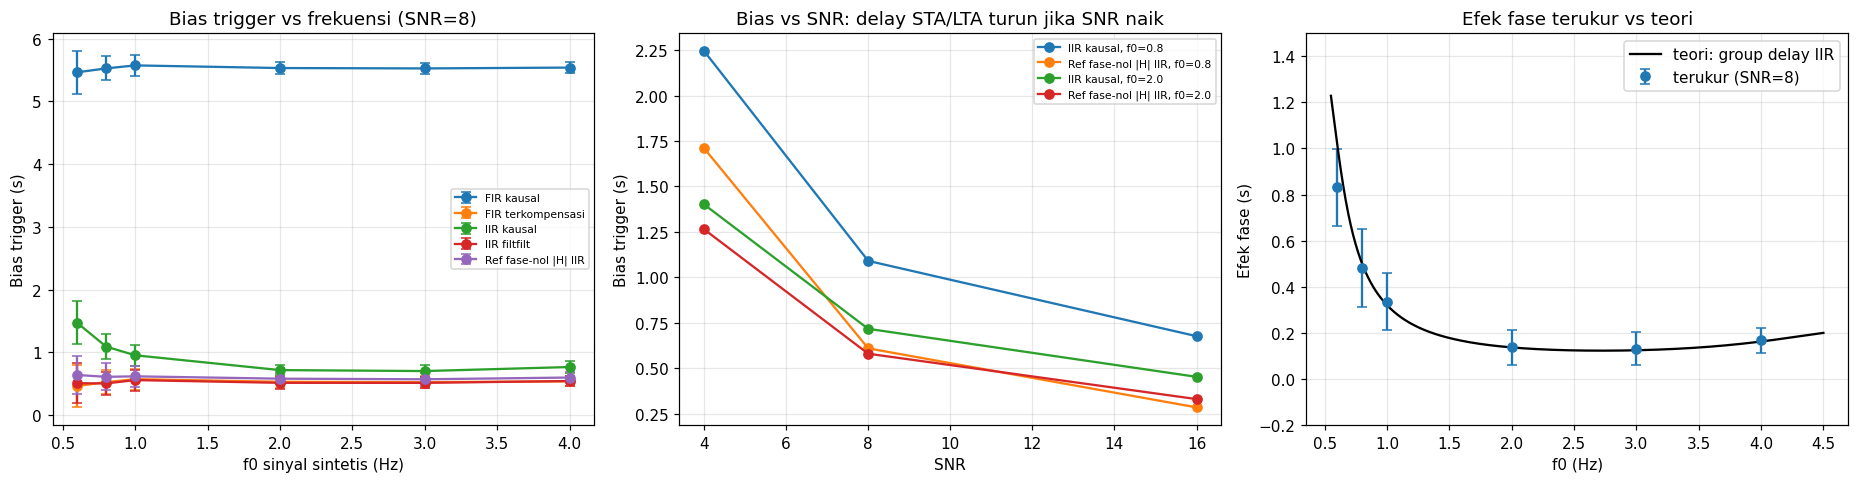

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k in PIPE_NAMES:
    s = resA[(resA.pipeline == k) & (resA.snr == 8)]
    ax[0].errorbar(s.f0, s.bias_mean, s.bias_sd, marker="o", capsize=3, label=k)
ax[0].set(xlabel="f0 sinyal sintetis (Hz)", ylabel="Bias trigger (s)", title="Bias trigger vs frekuensi (SNR=8)"); ax[0].legend(fontsize=7)

for f0 in [0.8, 2.0]:
    for k in ["IIR kausal", "Ref fase-nol |H| IIR"]:
        s = resA[(resA.pipeline == k) & (resA.f0 == f0)]
        ax[1].plot(s.snr, s.bias_mean, "o-", label=f"{k}, f0={f0}")
ax[1].set(xlabel="SNR", ylabel="Bias trigger (s)", title="Bias vs SNR: delay STA/LTA turun jika SNR naik"); ax[1].legend(fontsize=7)

e = ef[ef.snr == 8].sort_values("f0")
ax[2].errorbar(e.f0, e.bias_mean, e.bias_sd, fmt="o", capsize=3, label="terukur (SNR=8)")
ff = np.linspace(0.55, 4.5, 400); ax[2].plot(ff, group_delay_sos(sos, ff), "k-", label="teori: group delay IIR")
ax[2].set(xlabel="f0 (Hz)", ylabel="Efek fase (s)", title="Efek fase terukur vs teori", ylim=(-0.2, 1.5)); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR/"02_eksperimen_A_bias.png", bbox_inches="tight"); plt.show()

### hasil Eksperimen A
* **Selisih FIR kausal − terkompensasi = 5,000 s** → implementasi benar dan sesuai teori (group delay konstan).
* **Efek fase IIR ≈ τ_g(f₀)**: kecil (~0,1 s) untuk f₀ 2–4 Hz, tetapi **membesar mendekati tepi bawah pita** (0,6–0,8 Hz). Artinya bias fase sangat bergantung pada kandungan frekuensi sinyal, dan tremor vulkanik sering berada di frekuensi rendah.
* Pada SNR rendah banyak trial gagal memicu (`miss`), dan SD membesar. Ini batas praktis detektor, bukan kesalahan filter.
* **Bias absolut (mis. 0,4–2 s) didominasi oleh STA/LTA sendiri dan SNR**, bukan oleh fase filter. Fase hanya menambah geseran sistematis yang bisa diprediksi.

## 5. Eksperimen B: data nyata erupsi Kelud

Sekarang pipeline yang sama dijalankan pada seluruh rekaman. Untuk setiap event yang terdeteksi kita bandingkan waktu trigger antar-filter, lalu cocokkan selisihnya dengan **group delay pada frekuensi dominan event** (dihitung dengan Welch).

Peristiwa penting dari literatur (semua waktu UTC, 13 Feb 2014) dipasang sebagai garis bantu pada gambar. Ini **perkiraan** dari sumber tertulis, bukan pick dari data:
* ledakan awal ~15:46 (Maeno dkk.), meski sumber lain memberi 15:43–15:50
* perkiraan tiba S_P1 di JAGI ~15:54, dihitung dari origin dan celerity Caudron dkk. (2015) untuk jarak 211 km
* tremor kontinu mulai ~16:01 (Maeno dkk., mengutip Nakashima dkk.)
* perkiraan tiba S_P2/S_LL di JAGI ~16:12
* tremor berakhir ~18:00–18:30 (Maeno dkk.)

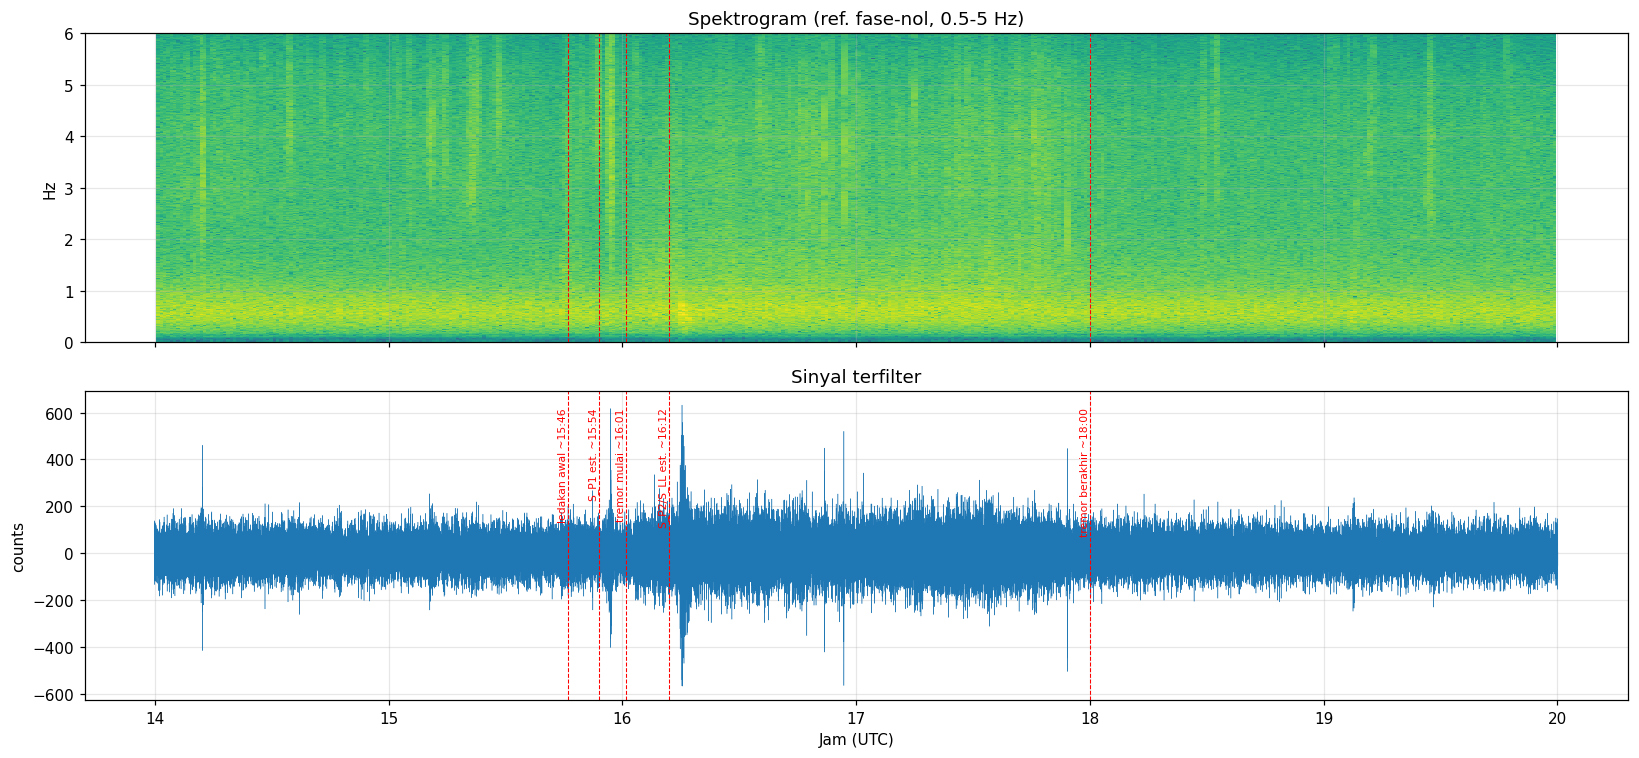

In [10]:
x = x_all - np.median(x_all)
real = apply_pipelines(x)
cf_real = {k: sta_lta(y) for k, y in real.items()}
for k in cf_real: cf_real[k][is_warm] = np.nan

ref = real["Ref fase-nol |H| IIR"]
i_an = np.flatnonzero(~is_warm)[0]
f_s, t_s, S = signal.spectrogram(ref[i_an:], fs=FS, nperseg=2048, noverlap=1024)
fig, ax = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
ax[0].pcolormesh(t_s/3600 + 14, f_s, 10*np.log10(S + 1e-9), shading="auto"); ax[0].set(ylim=(0, 6), ylabel="Hz", title="Spektrogram (ref. fase-nol, 0.5-5 Hz)")
t_hr = (np.arange(len(ref)) / FS) / 3600 + (T0_UTC.hour + T0_UTC.minute/60 + T0_UTC.second/3600)
m = ~is_warm; ax[1].plot(t_hr[m], ref[m], lw=.3); ax[1].set(xlabel="Jam (UTC)", ylabel="counts", title="Sinyal terfilter")
marks = {"ledakan awal ~15:46": 15 + 46/60, "S_P1 est. ~15:54": 15 + 54/60, "tremor mulai ~16:01": 16 + 1/60,
         "S_P2/S_LL est. ~16:12": 16 + 12/60, "tremor berakhir ~18:00": 18.0}
for a in ax:
    for lab, hh in marks.items(): a.axvline(hh, color="r", ls="--", lw=.7)
for lab, hh in marks.items(): ax[1].text(hh, ax[1].get_ylim()[1]*0.9, lab, rotation=90, fontsize=7, va="top", ha="right", color="r")
plt.tight_layout(); plt.savefig(FIG_DIR/"03_spektrogram_waveform.png", bbox_inches="tight"); plt.show()

In [11]:
ON_B, OFF_B, STRONG = 5.0, 1.5, 6.0
ev_ref = [e for e in detect_events(cf_real["Ref fase-nol |H| IIR"], ON_B, OFF_B) if e[2] >= STRONG]
print(f"Event kuat (CF_max >= {STRONG}) pada pipeline referensi: {len(ev_ref)}")

def match_trigger(cf, i_ref, tol_s=40):
    lo, hi = max(0, i_ref - int(tol_s*FS)), min(len(cf), i_ref + int(tol_s*FS))
    hit = np.flatnonzero(np.nan_to_num(cf[lo:hi]) >= ON_B)
    return lo + hit[0] if hit.size else None

rows = []
for (i0, i1, cmax) in ev_ref:
    seg = ref[i0: i0 + int(60*FS)]
    fw, pw = signal.welch(seg, fs=FS, nperseg=min(256, len(seg)))
    band = (fw >= F_LO) & (fw <= F_HI); f_dom = fw[band][np.argmax(pw[band])]
    f_cen = float(np.sum(fw[band] * pw[band]) / np.sum(pw[band]))
    row = dict(waktu_utc=utc(i0).strftime("%H:%M:%S"), cf_max=round(cmax, 1), f_dom_Hz=round(f_dom, 2),
               f_centroid_Hz=round(f_cen, 2), gd_teori_s=round(float(group_delay_sos(sos, f_dom)), 2),
               gd_teori_centroid_s=round(float(group_delay_sos(sos, f_cen)), 2))
    for k in ["IIR kausal", "IIR filtfilt", "FIR kausal", "FIR terkompensasi"]:
        j = match_trigger(cf_real[k], i0); row[k] = (j - i0)/FS if j is not None else np.nan
    pre  = np.sqrt(np.mean(ref[i0 - int(30*FS): i0 - int(5*FS)] ** 2))
    coda = np.sqrt(np.mean(ref[i0 + int(8*FS): i0 + int(40*FS)] ** 2))
    row["coda_rasio"] = round(coda / pre, 2)
    row["jenis"] = "berkelanjutan" if coda / pre >= 2 else "transien (tanpa coda)"
    row["dIIR_kausal"] = row["IIR kausal"] - 0.0
    row["dFIR_kaus-komp"] = row["FIR kausal"] - row["FIR terkompensasi"]
    rows.append(row)
resB = pd.DataFrame(rows)
resB.to_csv("hasil_eksperimen_B.csv", index=False)
cols = ["waktu_utc","cf_max","f_dom_Hz","f_centroid_Hz","gd_teori_s","gd_teori_centroid_s","coda_rasio","jenis","dIIR_kausal","IIR filtfilt","dFIR_kaus-komp"]
print(resB[cols].round(2).to_string(index=False))
if len(resB):
    print(f"\nRata-rata efek fase IIR terukur: {resB.dIIR_kausal.mean():.2f} s  | teori di f_dom: {resB.gd_teori_s.mean():.2f} s  | teori di centroid: {resB.gd_teori_centroid_s.mean():.2f} s")
    print("Catatan: selisih per-event berisik (resolusi 0.05 s, CF pada derau nyata, sinyal pita lebar). Laporkan sebaran, bukan hanya rata-rata.")
    print(f"FIR kausal - terkompensasi: {resB['dFIR_kaus-komp'].mean():.2f} s (harus 5.00)")

Event kuat (CF_max >= 6.0) pada pipeline referensi: 4
waktu_utc  cf_max  f_dom_Hz  f_centroid_Hz  gd_teori_s  gd_teori_centroid_s  coda_rasio                 jenis  dIIR_kausal  IIR filtfilt  dFIR_kaus-komp
 15:52:26     6.1      0.55           0.96        1.24                 0.34        0.85 transien (tanpa coda)         1.15          1.00             5.0
 15:57:00     6.5      0.62           2.29        0.92                 0.13        0.95 transien (tanpa coda)         0.25         -0.65             5.0
 16:14:51     7.7      0.55           0.68        1.24                 0.73        3.42         berkelanjutan         0.95          0.55             5.0
 17:54:14     8.0      0.62           0.83        0.92                 0.47        1.18 transien (tanpa coda)         0.10         -0.35             5.0

Rata-rata efek fase IIR terukur: 0.61 s  | teori di f_dom: 1.08 s  | teori di centroid: 0.42 s
Catatan: selisih per-event berisik (resolusi 0.05 s, CF pada derau nyata, sinyal pita

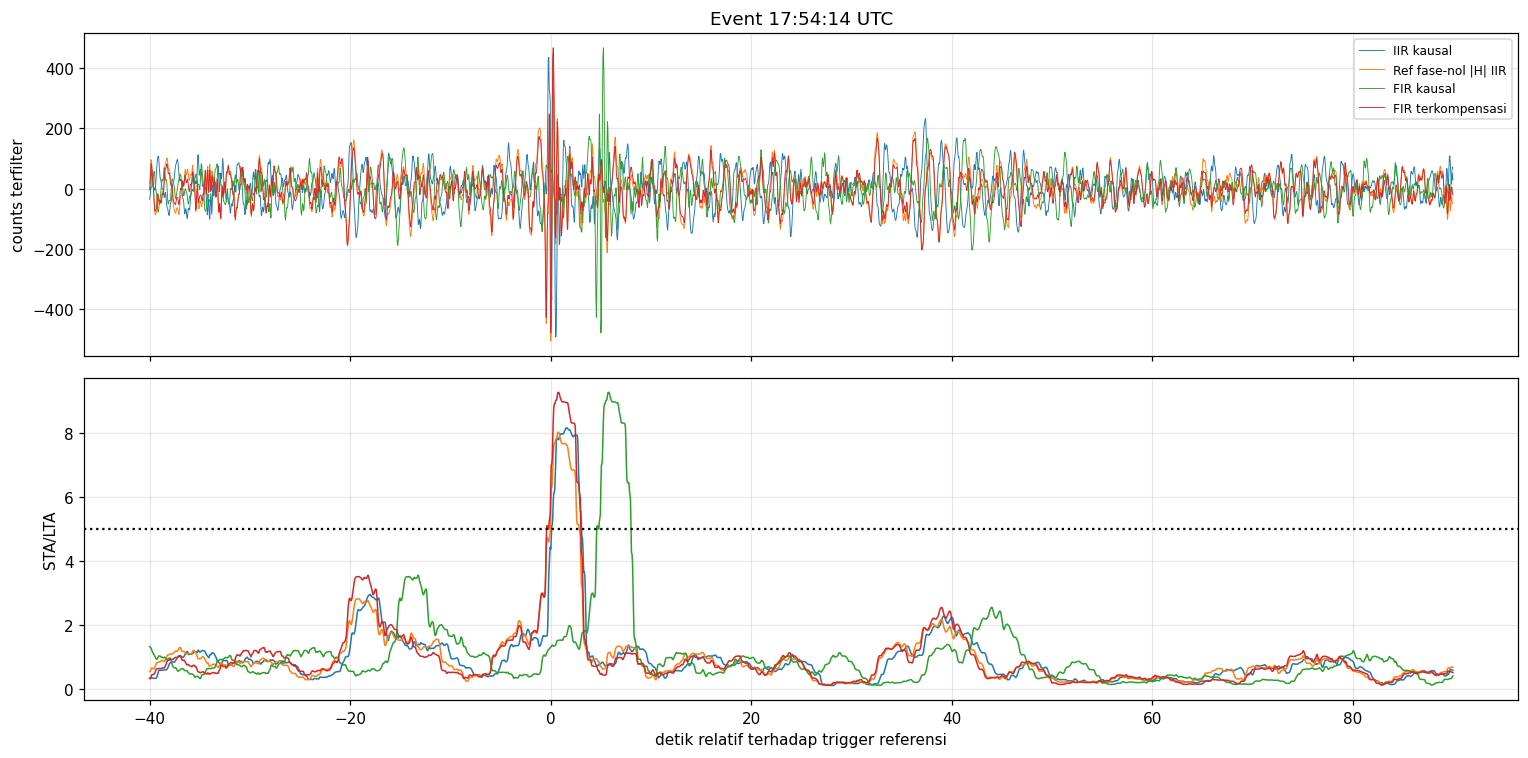

In [12]:
if len(resB):
    i0 = ev_ref[int(np.argmax([e[2] for e in ev_ref]))][0]
    sl = slice(i0 - int(40*FS), i0 + int(90*FS)); tt = (np.arange(len(x))[sl] - i0) / FS
    fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    for k in ["IIR kausal", "Ref fase-nol |H| IIR", "FIR kausal", "FIR terkompensasi"]:
        ax[0].plot(tt, real[k][sl], lw=.6, label=k); ax[1].plot(tt, cf_real[k][sl], lw=1, label=k)
    ax[1].axhline(ON_B, color="k", ls=":"); ax[0].set(ylabel="counts terfilter", title=f"Event {utc(i0):%H:%M:%S} UTC"); ax[1].set(xlabel="detik relatif terhadap trigger referensi", ylabel="STA/LTA")
    ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR/"04_event_terkuat_perbandingan.png", bbox_inches="tight"); plt.show()

CF tertinggi: 8.0 pada 17:54:15 UTC


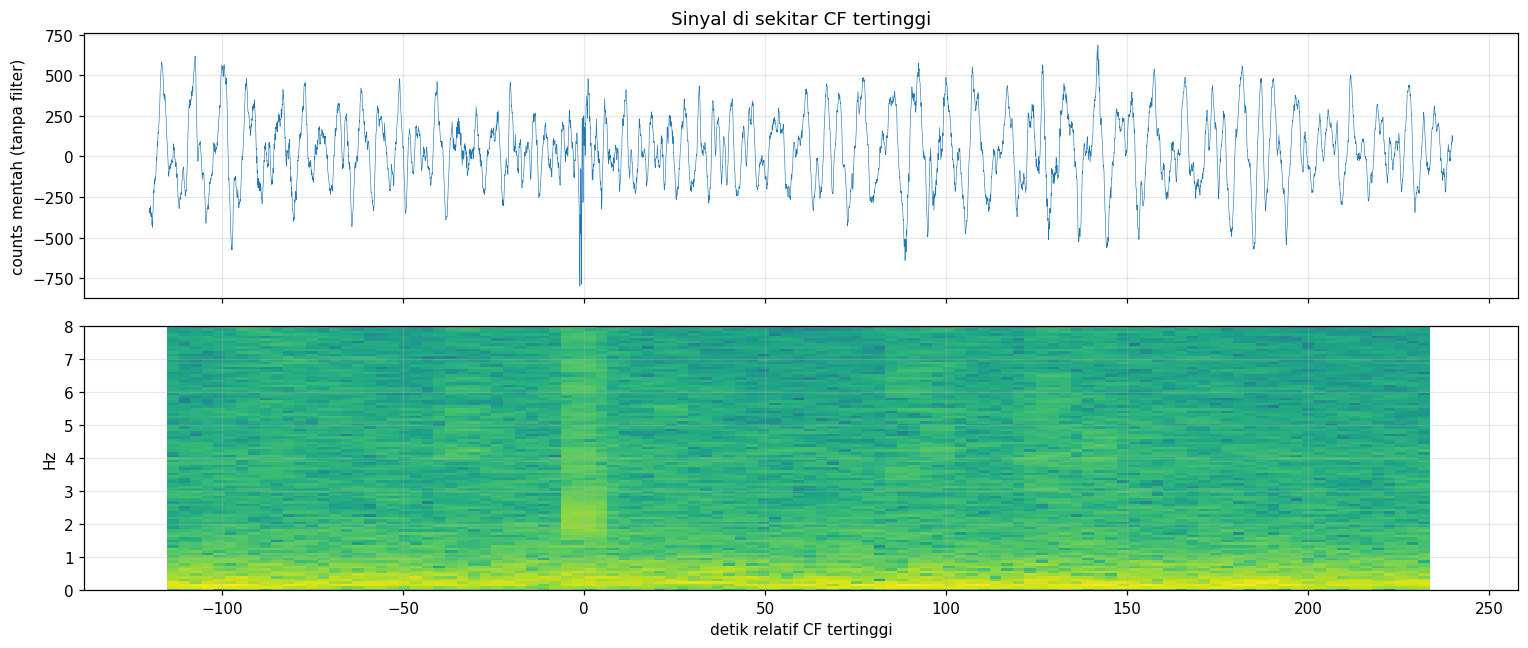

Cek manual: apakah ada onset impulsif berfrekuensi tinggi (gempa tektonik) atau hanya lonjakan di akhir tremor?


In [13]:
cf_ref = cf_real["Ref fase-nol |H| IIR"]
j = int(np.nanargmax(cf_ref)); print("CF tertinggi:", round(float(cf_ref[j]), 1), "pada", utc(j).strftime("%H:%M:%S"), "UTC")
sl = slice(j - int(120*FS), j + int(240*FS)); tt = (np.arange(len(ref))[sl] - j) / FS
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(tt, x[sl], lw=.4); ax[0].set(ylabel="counts mentah (tanpa filter)", title="Sinyal di sekitar CF tertinggi")
f_, t_, S_ = signal.spectrogram(x[sl], fs=FS, nperseg=256, noverlap=192)
ax[1].pcolormesh(t_ - 120, f_, 10*np.log10(S_ + 1e-9), shading="auto"); ax[1].set(ylim=(0, 8), xlabel="detik relatif CF tertinggi", ylabel="Hz")
plt.tight_layout(); plt.savefig(FIG_DIR/"05_cf_tertinggi_diselidiki.png", bbox_inches="tight"); plt.show()
print("Cek manual: apakah ada onset impulsif berfrekuensi tinggi (gempa tektonik) atau hanya lonjakan di akhir tremor?")

### hasil Eksperimen B
* Selisih **FIR kausal − terkompensasi = 5,00 s** di setiap event → implementasi benar.
* **Efek fase IIR pada data nyata jauh lebih berisik daripada pada data sintetis.** Alasannya: sinyal tremor berpita lebar (bukan satu frekuensi), CF pada derau nyata naik-turun, dan resolusi waktu hanya 0,05 s. Jangan memaksa angkanya cocok dengan teori; laporkan **sebaran** dan jelaskan penyebabnya.
* Frekuensi dominan (Welch) yang jatuh di **0,5–0,6 Hz** berada tepat di tepi pita filter. Ini sebagian bisa merupakan artefak spektrum "merah" (energi derau frekuensi rendah menurun ke arah atas), jadi bandingkan juga dengan **centroid spektral**. Group delay IIR berubah cepat di daerah ini (≈1,4 s di 0,5 Hz vs ≈0,7 s di 0,7 Hz), sehingga ketidakpastian f₀ sebesar 0,1 Hz saja sudah mengubah prediksi lebih dari setengah detik.
* Temuan metodologis yang kuat: **pilihan tepi bawah pita menentukan besar bias fase.** Uji sensitivitas yang mudah: ulangi dengan `F_LO = 1.0` dan lihat apakah efek fase mengecil.
* **Periksa kolom `jenis`/`coda_rasio`.** Pada data ini, tiga dari empat event kuat (sekitar 15:52, 15:57, 17:54 UTC) adalah **transien singkat tanpa coda** (rasio coda ≈ 1), bentuknya seperti lonjakan, bukan gempa atau tremor. Hanya event sekitar 16:14 UTC yang berenergi **berkelanjutan** (rasio coda > 3), dan itu sesuai dengan perkiraan tiba S_P2/S_LL (~16:12) serta jendela tremor. Lonjakan impulsif seperti ini mirip yang dibahas Gunawan dkk. (2012) sebagai *spiking* (guncangan listrik/grounding), dan mereka menyaringnya dengan uji rasio amplitudo. Jadi: (a) jangan memberi label S_P1/S_P2 pada transien itu tanpa bukti tambahan, (b) pertimbangkan membuang lonjakan sebelum STA/LTA dan laporkan pengaruhnya, (c) perbandingan bias fase yang paling bisa dipercaya pada data nyata adalah event berkelanjutan, ditambah Eksperimen A.

## 6. Opsional: koreksi respons instrumen (uji sensitivitas)

Data CSV masih berupa *counts*. Untuk detektor dan perbandingan fase ini cukup, tetapi di laporan tulis sebagai keterbatasan. Sel di bawah mengunduh metadata (StationXML) JAGI dari GEOFON, mengubah ke kecepatan (µm/s), lalu menghitung ulang event terkuat. **Butuh internet.** Ubah `RUN_OPTIONAL = True` untuk menjalankan. Sel ini belum diuji di lingkungan penulis (tidak ada akses jaringan ke GEOFON), jadi laporkan kalau ada error.

In [14]:
RUN_OPTIONAL = False

if RUN_OPTIONAL:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "obspy"], check=True)
    from obspy import Trace, UTCDateTime
    from obspy.clients.fdsn import Client

    tr = Trace(data=x_all.copy())
    tr.stats.update(dict(sampling_rate=FS, starttime=UTCDateTime(T0_UTC.to_pydatetime()),
                         network="GE", station="JAGI", location="", channel="BHZ"))
    inv = Client("GFZ").get_stations(network="GE", station="JAGI", channel="BHZ",
                                      starttime=tr.stats.starttime, endtime=tr.stats.endtime, level="response")
    tr_v = tr.copy().remove_response(inventory=inv, output="VEL", pre_filt=(0.05, 0.1, 8, 9.5), water_level=60)
    x_vel = tr_v.data * 1e6
    ref_v = zero_phase_magnitude(x_vel - np.median(x_vel))
    cf_v = sta_lta(ref_v); cf_v[is_warm] = np.nan
    ev_v = [e for e in detect_events(cf_v, ON_B, OFF_B) if e[2] >= STRONG]
    print("Event kuat setelah koreksi instrumen:", [(utc(e[0]).strftime("%H:%M:%S"), round(e[2], 1)) for e in ev_v])
    print("Bandingkan dengan sebelum koreksi: ", [(utc(e[0]).strftime("%H:%M:%S"), round(e[2], 1)) for e in ev_ref])
else:
    print("Bagian opsional dilewati (RUN_OPTIONAL = False).")

Bagian opsional dilewati (RUN_OPTIONAL = False).


## 7. Ringkasan untuk laporan

**Temuan yang bisa ditulis (isi angka dari hasil run-mu sendiri, jangan menyalin angka dari catatan ini):**
1. FIR fase-linear: pergeseran = (N−1)/2/fs, konstan dan bisa dikompensasi; tetapi kompensasi bersifat **akausal** (tidak untuk real-time).
2. IIR kausal: pergeseran = group delay pada frekuensi dominan, kecil di tengah pita dan **membesar di tepi bawah pita** (0,5–1 Hz), tempat energi tremor vulkanik sering berada.
3. Prediksi teori vs hasil terukur (Eksperimen A dan B): laporkan galat dalam detik dan batas resolusi (1 sampel = 0,05 s).
4. Bias absolut trigger didominasi oleh STA/LTA dan SNR; efek fase adalah komponen sistematis tambahan.

**Keterbatasan (wajib ditulis):**
* Satu stasiun dan satu erupsi. Hasil Eksperimen A bergantung pada bentuk wavelet sintetis (sinusoid teredam).
* Data berupa counts (belum dikoreksi instrumen, lihat bagian 6).
* Tidak ada katalog resmi onset di JAGI; ground truth hanya sintetis.
* Parameter STA/LTA (3 s/60 s, ambang) dipilih sebagai acuan; laporkan sensitivitasnya jika sempat.
* Event pada Eksperimen B dipilih dengan ambang CF, sehingga hanya event yang cukup kuat yang dibandingkan.

**Pengembangan opsional:** tambahkan penghalus AIC (Guided-AIC, lihat Arifin & Nugraha 2015) dan tanyakan apakah AIC mengurangi bias fase; tambahkan stasiun pembanding (GE-UGM, GE-SMRI, GE-PLAI).

## Daftar pustaka (sudah dibaca isinya, kecuali yang bertanda *)
* Arifin, J., & Nugraha, J. (2015). Teknik identifikasi polaritas dan kualitas impulse pertama gelombang P dan penentuan magnitudo gempabumi dalam sistem monitoring gempabumi JISView. *Jurnal Meteorologi dan Geofisika, 16*(2), 123–134.
* Gunawan, H., Puspito, N. T., Ibrahim, G., Haryadi, P. J. P., & Kadnan. (2012). Penentuan waktu tiba gelombang-P secara otomatis dengan metoda skewness dan kurtosis terintegrasi. *Jurnal Meteorologi dan Geofisika, 13*(1), 63–69.
* Hielmy, R. I., Pranata, B., Wijayanto, & Daryono. (2025). Performance evaluation of automated and manual seismic phase picking for rapid earthquake parameter determination in the Indonesian BMKG network. *Jurnal Meteorologi dan Geofisika, 26*(2), 89–107.
* Nur, B. A. A., Hasib, M., & Kriswati, E. (2025). Machine learning for fully automated detection of volcanic seismic signals in real seismic records at Sinabung Volcano, North Sumatra. *Rudarsko-geološko-naftni zbornik, 40*(4), 99–110. https://doi.org/10.17794/rgn.2025.4.8
* Caudron, C., Taisne, B., Garcés, M., Le Pichon, A., & Mialle, P. (2015). On the use of remote infrasound and seismic stations to constrain the eruptive sequence and intensity for the 2014 Kelud eruption. *Geophysical Research Letters, 42*, 6614–6621. https://doi.org/10.1002/2015GL064885
* Maeno, F., Nakada, S., Yoshimoto, M., Shimano, T., Hokanishi, N., Zaennudin, A., & Iguchi, M. A sequence of a plinian eruption preceded by dome destruction at Kelud volcano, Indonesia, on February 13, 2014, revealed from tephra fallout and pyroclastic density current deposits. *Journal of Volcanology and Geothermal Research.* https://doi.org/10.1016/j.jvolgeores.2017.03.002 *(volume dan halaman final: lengkapi dari halaman DOI)*
* Zhang, H., Thurber, C., & Rowe, C. (2003). Automatic P-wave arrival detection and picking with multiscale wavelet analysis for single-component recordings. *Bulletin of the Seismological Society of America, 93*(5), 1904–1912. https://doi.org/10.1785/0120020241
* Trnkoczy, A. (2009). Understanding and parameter setting of STA/LTA trigger algorithm. Dalam *New Manual of Seismological Observatory Practice (NMSOP)*. GFZ. *(dikutip oleh Nur dkk. 2025; belum dibaca langsung)*
* Scherbaum, F. (1994). *Basic concepts in digital signal processing for seismologists.* Springer. *(dikutip Arifin & Nugraha 2015; belum dibaca, cari dulu sebelum disitasi)*
* Oppenheim, A. V., & Schafer, R. W. *Discrete-Time Signal Processing.* *(buku teks; lengkapi edisi dan tahun sesuai yang kamu pakai)*
* GEOFON Data Centre. (1993). GEOFON Seismic Network. GFZ. https://doi.org/10.14470/TR560404